In [1]:
#Importing the Libraries
import numpy as np
import pandas as pd
import datetime
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt, numpy as np
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import AgglomerativeClustering
from matplotlib.colors import ListedColormap
from sklearn import metrics
import warnings
import sys
if not sys.warnoptions:
    warnings.simplefilter("ignore")
np.random.seed(42)


### EDA and Preprocessing

In [2]:
df=pd.read_csv(r"marketing_campaign.csv", sep='\t')
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


In [3]:
print("Số hàng của bộ dữ liệu: ", df.shape[0])
print("Số cột của bộ dữ liệu: ", df.shape[1])

Số hàng của bộ dữ liệu:  2240
Số cột của bộ dữ liệu:  29


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [5]:
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

binary_cols = df.columns[df.nunique(dropna=True) == 2].tolist()

numeric_cols = df.select_dtypes(include=[np.number])
numeric_cols = numeric_cols.columns[numeric_cols.nunique(dropna=True) > 2].tolist()

# In ra kết quả, mỗi biến cách nhau bằng dấu phẩy và xuống dòng
print("Các biến không phải dạng số:", ", ".join(cat_cols))
print("Các biến dạng nhị phân:", ", ".join(binary_cols))
print("Các biến dạng số:", ", ".join(numeric_cols))


Các biến không phải dạng số: Education, Marital_Status, Dt_Customer
Các biến dạng nhị phân: AcceptedCmp3, AcceptedCmp4, AcceptedCmp5, AcceptedCmp1, AcceptedCmp2, Complain, Response
Các biến dạng số: ID, Year_Birth, Income, Kidhome, Teenhome, Recency, MntWines, MntFruits, MntMeatProducts, MntFishProducts, MntSweetProducts, MntGoldProds, NumDealsPurchases, NumWebPurchases, NumCatalogPurchases, NumStorePurchases, NumWebVisitsMonth


Unique

In [6]:
df.nunique()

ID                     2240
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             663
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         558
MntFishProducts         182
MntSweetProducts        177
MntGoldProds            213
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Z_CostContact             1
Z_Revenue                 1
Response                  2
dtype: int64

In [7]:
#vì chỉ có 1 giá trị nên không đóng góp vào quy trình phân cụm
df = df.drop(columns=['Z_CostContact', 'Z_Revenue','ID'])

In [8]:
print("Số hàng của bộ dữ liệu: ", df.shape[0])
print("Số cột của bộ dữ liệu: ", df.shape[1])

Số hàng của bộ dữ liệu:  2240
Số cột của bộ dữ liệu:  26


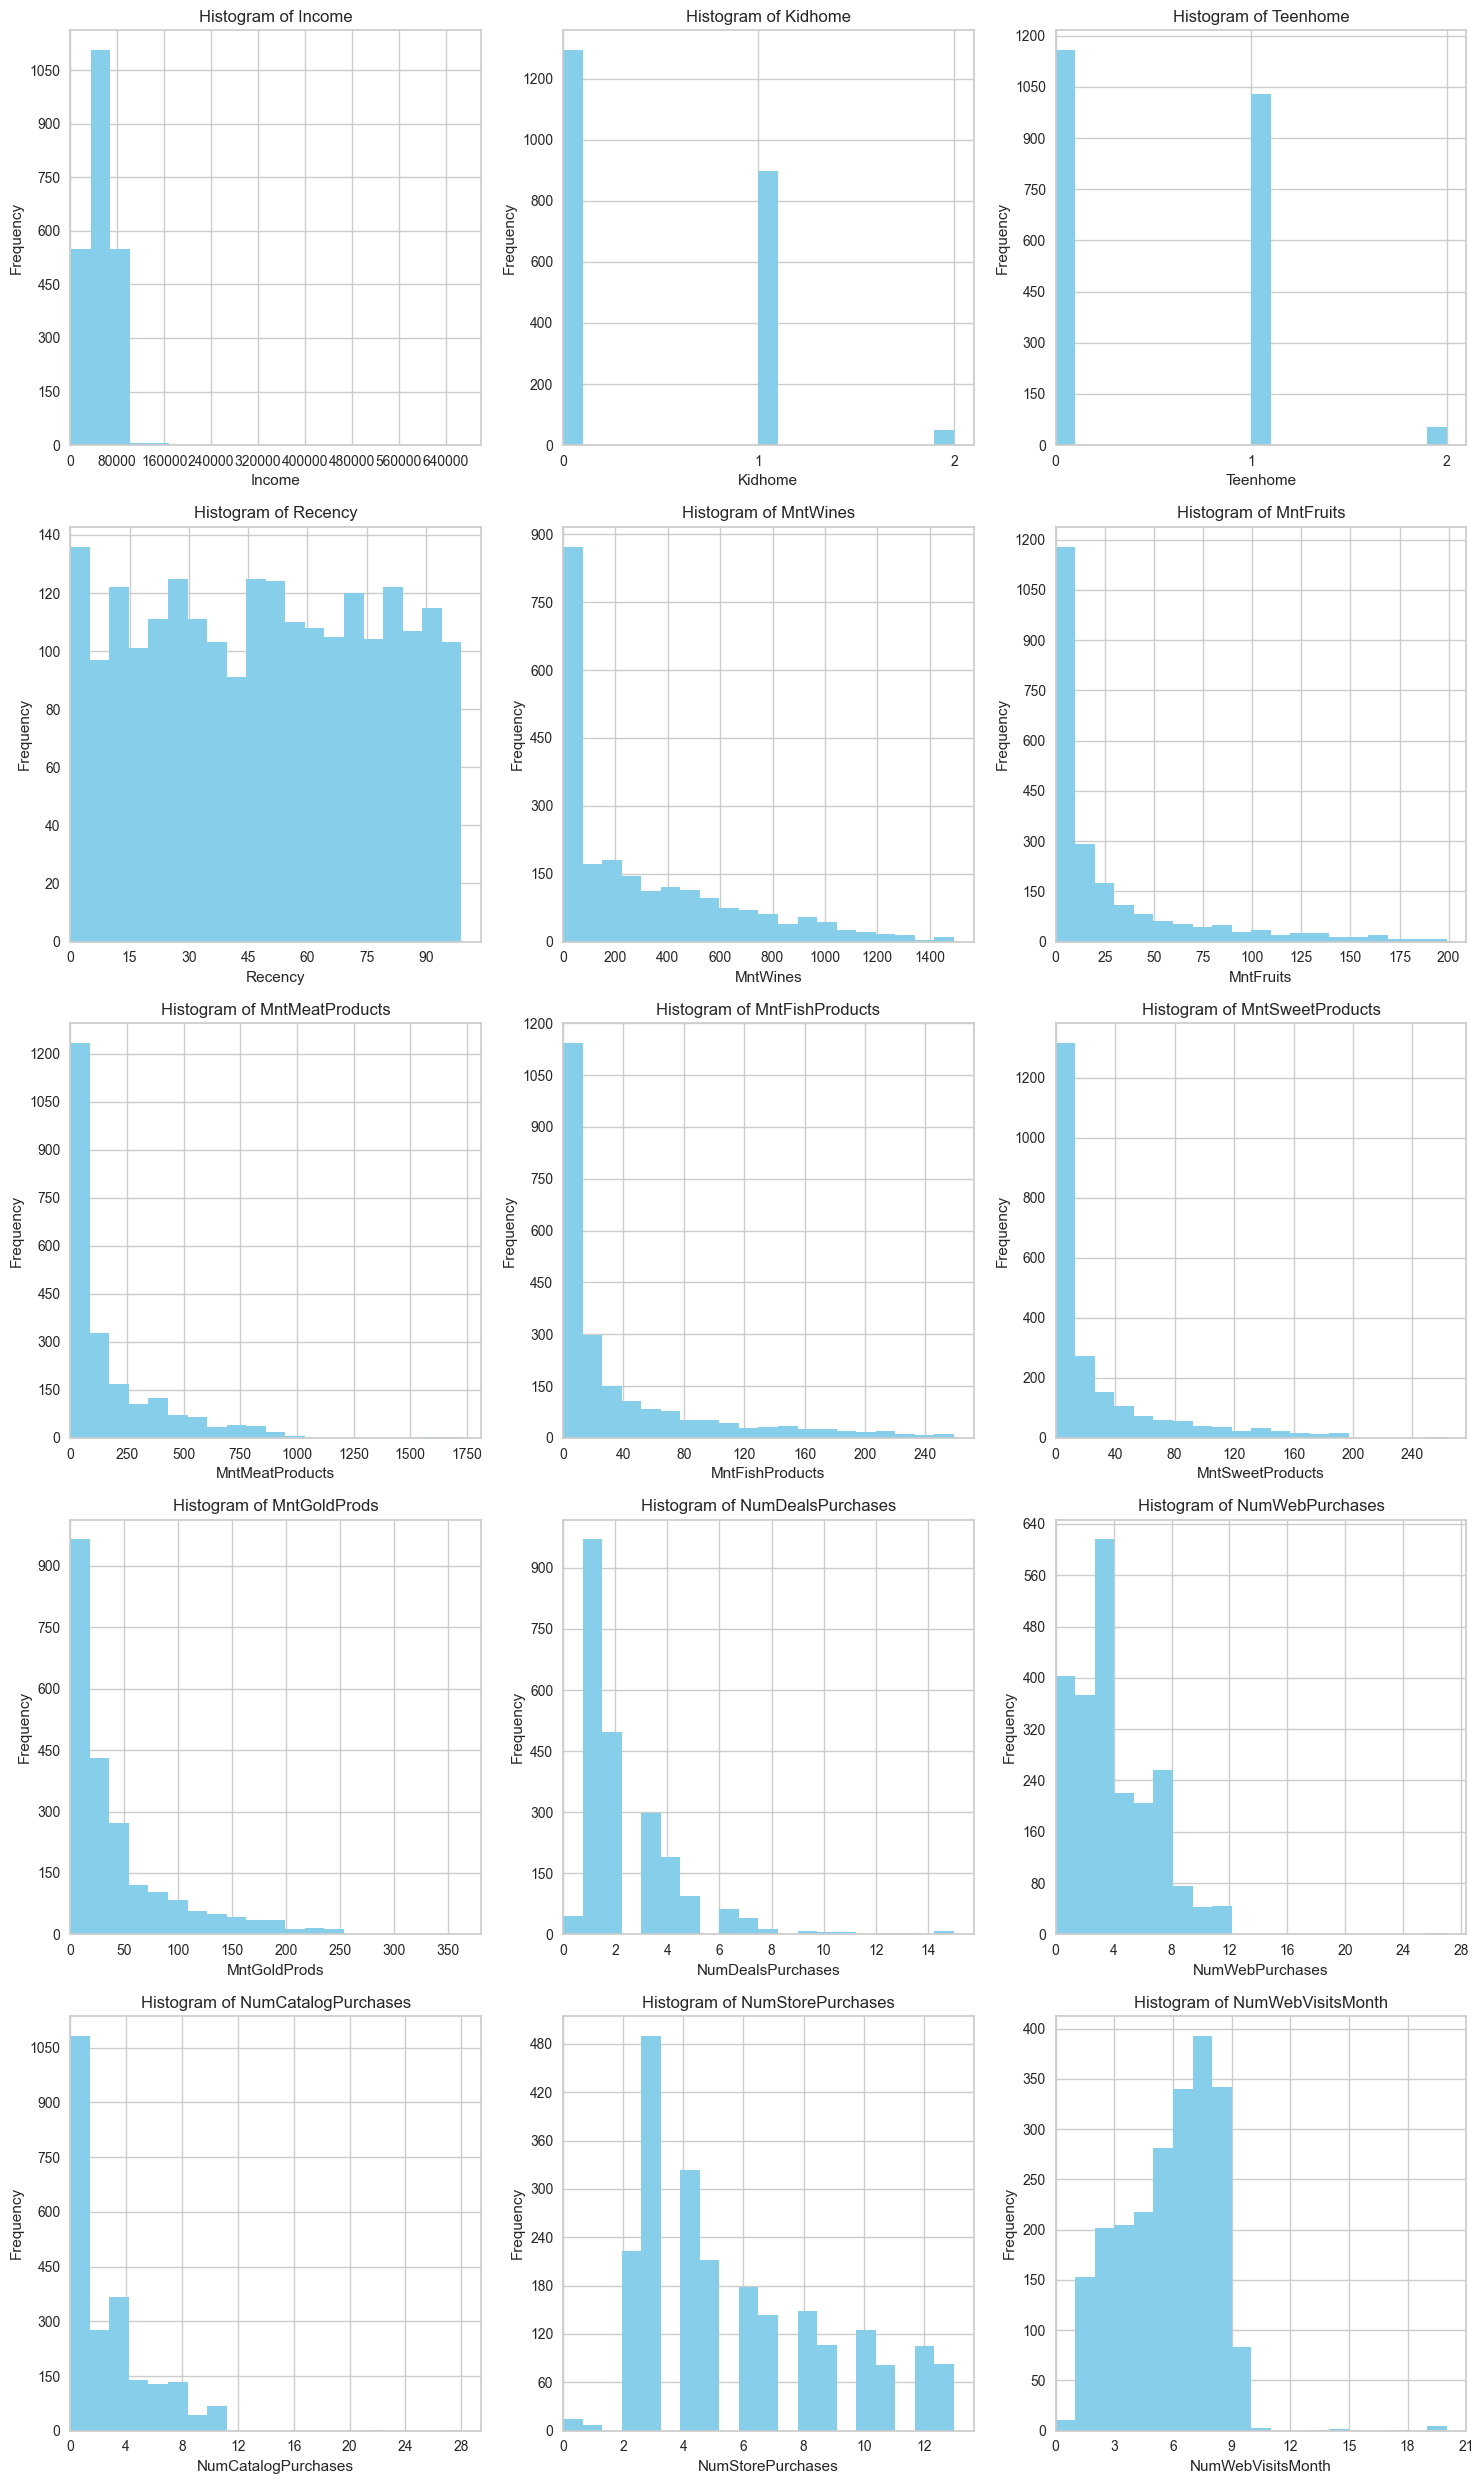

In [9]:
from matplotlib.ticker import MaxNLocator
# Danh sách các thuộc tính số
numeric_cols = ['Income', 'Kidhome', 'Teenhome', 'Recency', 
 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 
 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']
# Số lượng cột trong mỗi dòng
cols_per_row = 3
# Tính số lượng dòng cần tạo
num_rows = (len(numeric_cols) + cols_per_row - 1) // cols_per_row
# Vẽ biểu đồ histogram cho từng thuộc tính, chia mỗi dòng ba biểu đồ
fig, axes = plt.subplots(num_rows, cols_per_row, figsize=(15, 5*num_rows))
for i, column in enumerate(numeric_cols):
    row = i // cols_per_row
    col = i % cols_per_row
    ax = axes[row, col]
    ax.hist(df[column], bins=20, color='skyblue')
    # Xác định lại phạm vi trục x và y để trùng với gốc tọa độ (0,0)
    ax.set_xlim(left=0)  # Đặt phạm vi trục x từ 0
    ax.set_ylim(bottom=0)  # Đặt phạm vi trục y từ 0
    ax.set_title(f"Histogram of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel('Frequency')
    # Định dạng lại ticks trên trục x và trục y để chỉ hiển thị số 0 tại gốc tọa độ
    ax.xaxis.set_major_locator(MaxNLocator(nbins='auto', integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(nbins='auto', integer=True))
# Xóa các subplot còn thừa nếu có
for i in range(len(numeric_cols), num_rows * cols_per_row):
    row = i // cols_per_row
    col = i % cols_per_row
    fig.delaxes(axes[row, col])
plt.tight_layout()
plt.show()

null

In [10]:
df.isna().sum()

Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Response                0
dtype: int64

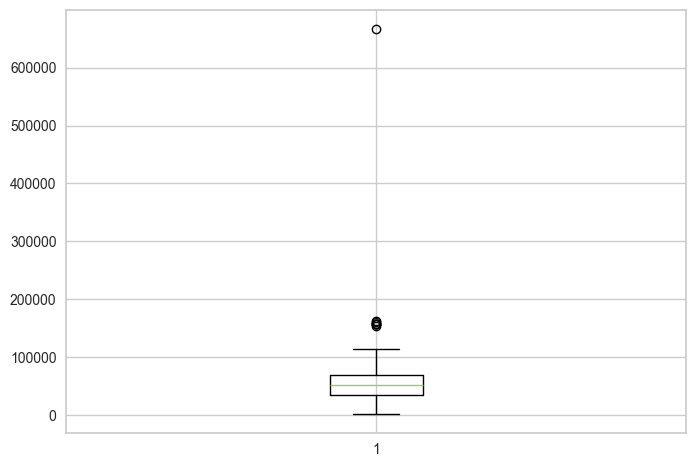

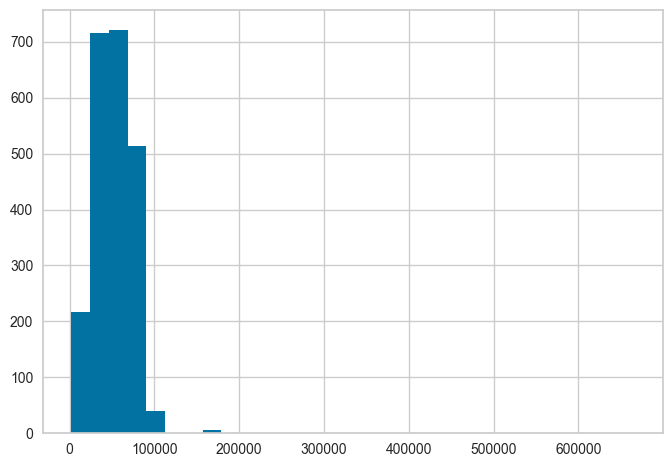

count      2216.000000
mean      52247.251354
std       25173.076661
min        1730.000000
25%       35303.000000
50%       51381.500000
75%       68522.000000
max      666666.000000
Name: Income, dtype: float64

In [11]:
#xử lí null ở income
plt.boxplot(df.Income.dropna())
plt.show()
plt.hist(df.Income.dropna(), bins=30)
plt.show()
df.Income.describe()

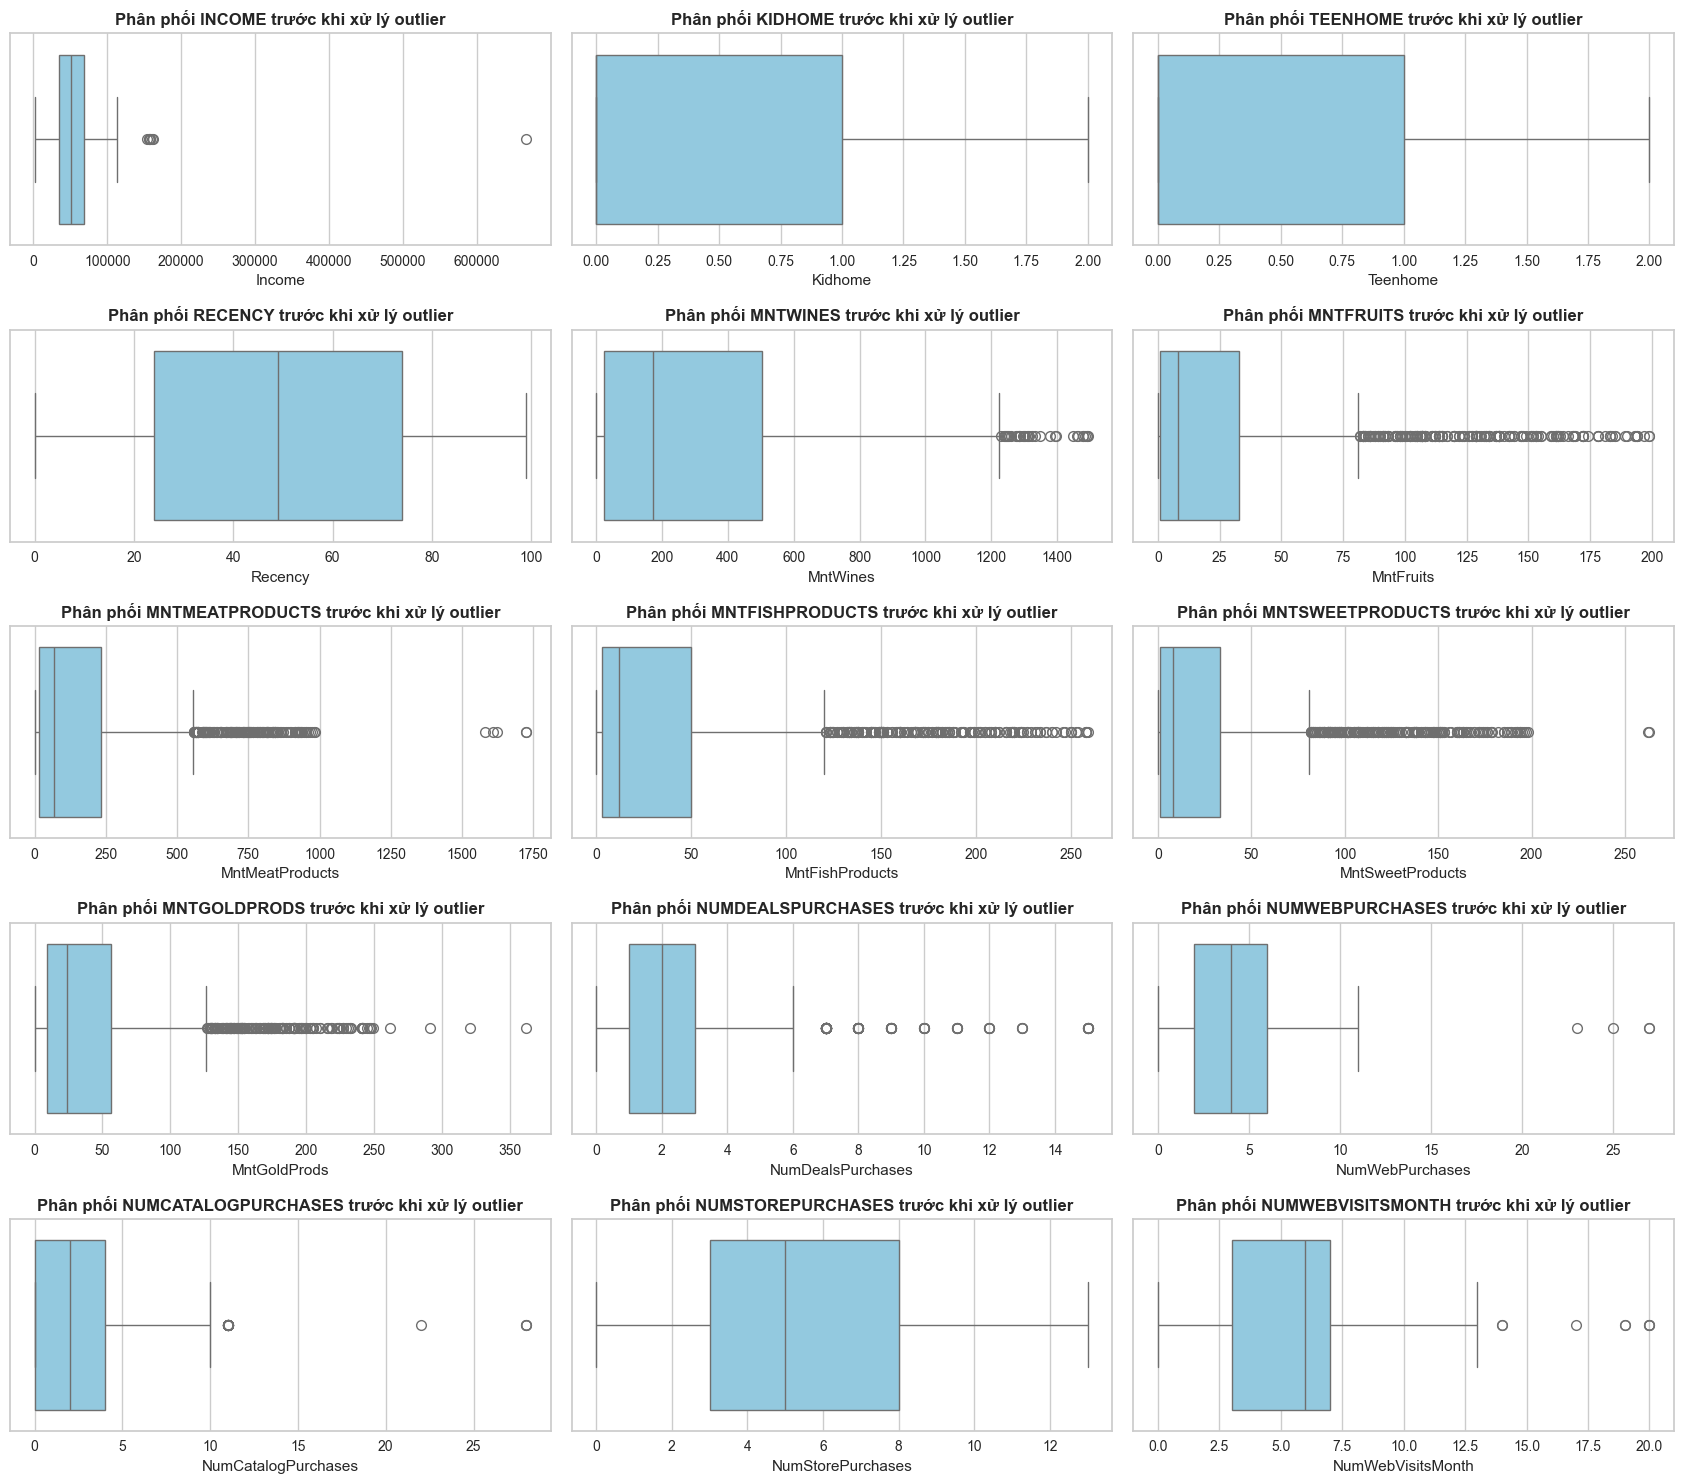

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

num_cols = len(numeric_cols)
ncols = 3
nrows = math.ceil(num_cols / ncols)  

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(17, 3 * nrows))
axes = np.array(axes).reshape(-1) 
for i, column in enumerate(numeric_cols):
    sns.boxplot(x=df[column], ax=axes[i], color='skyblue')
    axes[i].set_title(
        f'Phân phối {column.upper()} trước khi xử lý outlier',
        fontsize=12, fontweight='bold'
    )

# Ẩn các subplot thừa (nếu có)
for j in range(num_cols, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [13]:
## Số giá trị null không nhiều, outliers cũng ít ảnh hưởng điền bằng median
df['Income'].fillna(df['Income'].median(), inplace=True)

##Sẵn tiện coi  luôn so lượng giá trị lớn hơn q3 + 1.5*IQR
q3 = df.Income.quantile(0.75)
iqr = df.Income.quantile(0.75) - df.Income.quantile(0.25)
# 8 giá trị quá lớn nên bỏ qua
df = df[df.Income <= q3+ 1.5*iqr]

In [14]:
#chia biến theo loại để xử lí
people = [
     'Year_Birth', 'Education', 'Marital_Status', 'Income', 
    'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'Complain'
]

product = [
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 
    'MntSweetProducts', 'MntGoldProds'
]

promotion = [
    'NumDealsPurchases', 'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 
    'AcceptedCmp4', 'AcceptedCmp5', 'Response'
]

place = [
    'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 
    'NumWebVisitsMonth'
]

Xử lí nhóm PEOPLE

In [15]:
df[people].info()

<class 'pandas.core.frame.DataFrame'>
Index: 2232 entries, 0 to 2239
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year_Birth      2232 non-null   int64  
 1   Education       2232 non-null   object 
 2   Marital_Status  2232 non-null   object 
 3   Income          2232 non-null   float64
 4   Kidhome         2232 non-null   int64  
 5   Teenhome        2232 non-null   int64  
 6   Dt_Customer     2232 non-null   object 
 7   Recency         2232 non-null   int64  
 8   Complain        2232 non-null   int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 174.4+ KB


Tuổi

In [16]:
#chuyển Year-Birth thành tuổi
df['Year_Birth']= 2025 - df['Year_Birth']
df.Year_Birth

0       68
1       71
2       60
3       41
4       44
        ..
2235    58
2236    79
2237    44
2238    69
2239    71
Name: Year_Birth, Length: 2232, dtype: int64

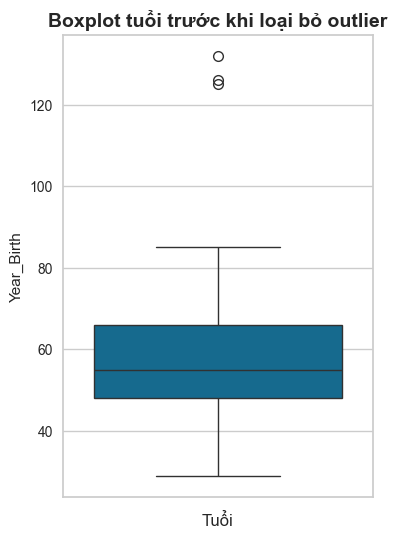

In [17]:
plt.figure(figsize=(4,6)) 
sns.boxplot(df.Year_Birth)
#lấy những người bé hơn 90 tuổi để loại bỏ Outliers
plt.title('Boxplot tuổi trước khi loại bỏ outlier', fontsize=14, fontweight='bold')
plt.xlabel('Tuổi', fontsize=12)
plt.show()
df =df[df.Year_Birth<=90]

In [18]:
df = df[df.Income <200000]
# Fill Income null values with mode
df['Income'] = df['Income'].fillna(df['Income'].median())


Học vấn

Education
Graduation    1124
PhD            481
Master         369
2n Cycle       201
Basic           54
Name: count, dtype: int64


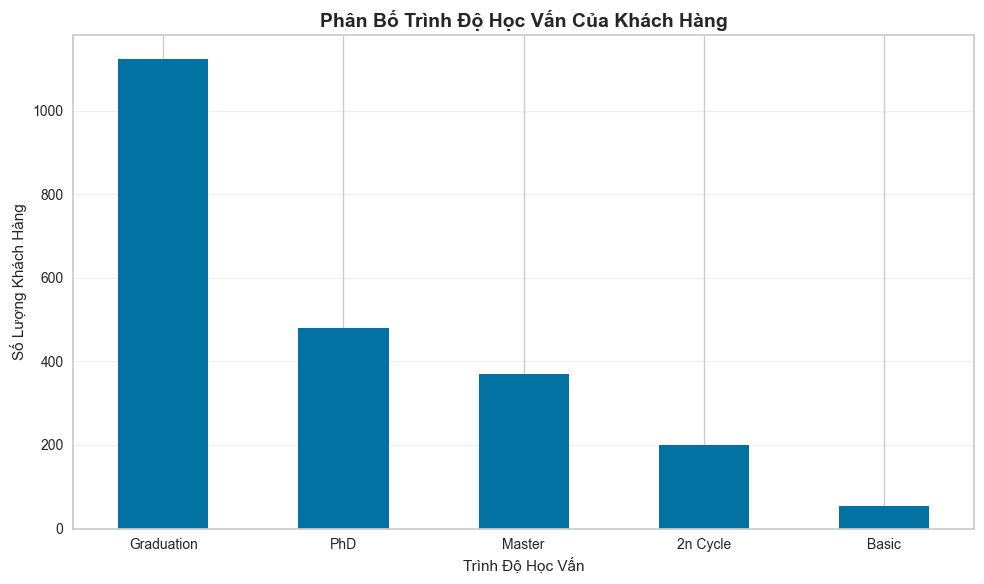

In [19]:
#Học vấn
print(df.Education.value_counts())

plt.figure(figsize=(10, 6))
df.Education.value_counts().plot(kind='bar')
plt.title('Phân Bố Trình Độ Học Vấn Của Khách Hàng', fontsize=14, fontweight='bold')
plt.xlabel('Trình Độ Học Vấn')
plt.xticks(rotation=0)
plt.ylabel('Số Lượng Khách Hàng')

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

tt hôn nhân

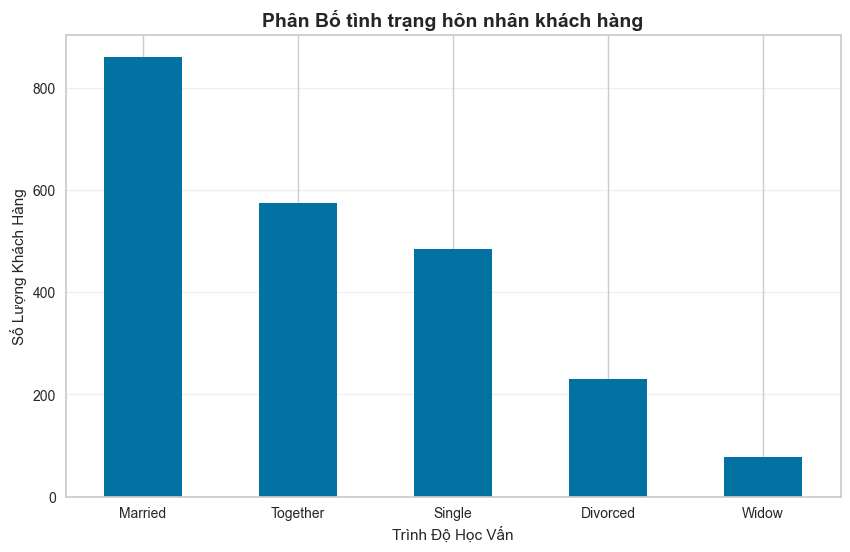

In [20]:
df.Marital_Status.value_counts()
#single và YOLO chỉ độc thân
df.Marital_Status = df.Marital_Status.replace(['Alone', 'YOLO'], 'Single')
#bỏ giá trị Absurd vì số lượng nhỏ và không có ý nghĩa
df = df[df.Marital_Status != 'Absurd']
df.Marital_Status.value_counts()

plt.figure(figsize=(10, 6))
df.Marital_Status.value_counts().plot(kind='bar')
plt.title('Phân Bố tình trạng hôn nhân khách hàng', fontsize=14, fontweight='bold')
plt.xlabel('Trình Độ Học Vấn')
plt.xticks(rotation=0)
plt.ylabel('Số Lượng Khách Hàng')

plt.grid(axis='y', alpha=0.3)

In [21]:
df.Income.describe()  #thu nhập đã xửu lí ở trên

count      2227.000000
mean      51600.872923
std       20600.045510
min        1730.000000
25%       35402.000000
50%       51381.500000
75%       68117.500000
max      113734.000000
Name: Income, dtype: float64

Text(0.5, 0, 'Số Lượng Trẻ Em/Thanh Thiếu Niên')

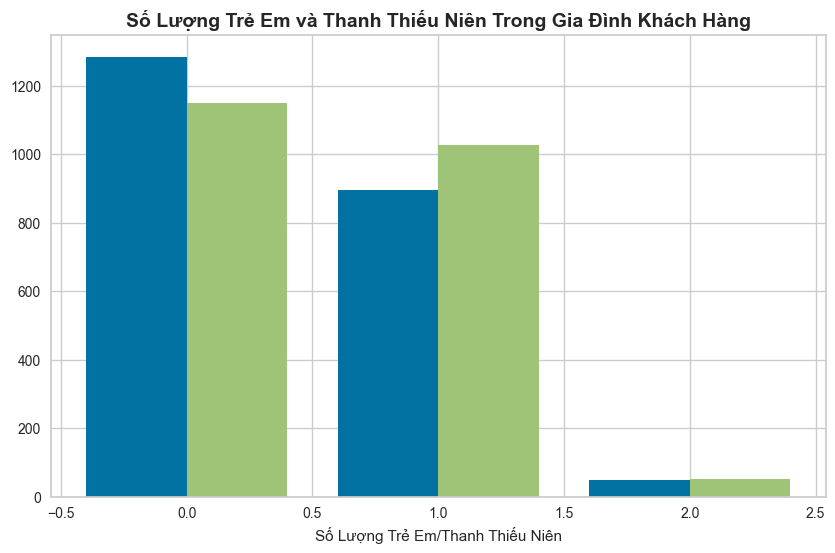

In [22]:
k = df.Kidhome.value_counts()
t = df.Teenhome.value_counts()

plt.figure(figsize=(10, 6))
plt.bar(k.index - 0.2, k.values, width=0.4, label='Kidhome')
plt.bar(t.index + 0.2, t.values, width=0.4, label='Teenhome')
plt.title('Số Lượng Trẻ Em và Thanh Thiếu Niên Trong Gia Đình Khách Hàng', fontsize=14, fontweight='bold')
plt.xlabel('Số Lượng Trẻ Em/Thanh Thiếu Niên')

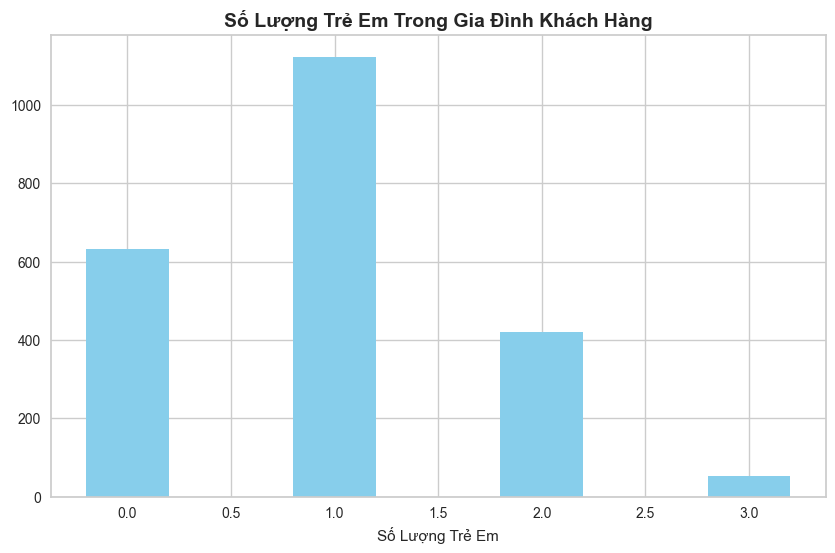

In [23]:
### gộp lại thành số lượng con trong gia đình
df['Children'] = df['Kidhome'] + df['Teenhome']
df.drop(columns=['Kidhome', 'Teenhome'], inplace=True)
c = df.Children.value_counts()  
plt.figure(figsize=(10, 6))
plt.bar(c.index, c.values, width=0.4, color='skyblue')
plt.title('Số Lượng Trẻ Em Trong Gia Đình Khách Hàng', fontsize=14, fontweight='bold')
plt.xlabel('Số Lượng Trẻ Em')
plt.show()

Ngày đăng kí thẻ thành viên

In [24]:
df['Dt_Customer']= pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')

#Chuyển thành số tháng từ khi đăng kí đến nay
df['Customer_for'] = (datetime.datetime.now() - df['Dt_Customer']).dt.days // 30
df.drop(columns=['Dt_Customer'], inplace=True)



In [25]:
df.Customer_for

0       160
1       142
2       148
3       142
4       143
       ... 
2235    151
2236    138
2237    143
2238    143
2239    159
Name: Customer_for, Length: 2227, dtype: int64

Số ngày kể từ lần mua cuối

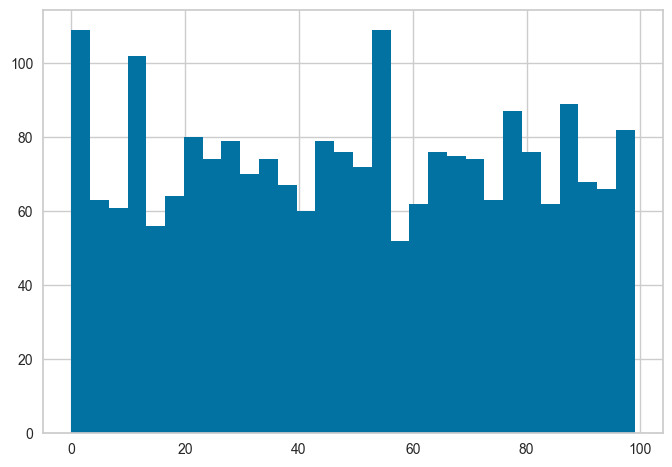

In [26]:
plt.hist(df.Recency, bins=30) #kiểm tra phân bố Recency
plt.show()

In [27]:
#Có khiếu nại không
df.Complain.value_counts()


Complain
0    2207
1      20
Name: count, dtype: int64

In [28]:
df = df.drop(columns=['Complain'])

In [29]:
#cập nhật lại nhóm People
people = [
     'Year_Birth', 'Education', 'Marital_Status', 'Income','Children','Customer_for','Recency']

In [30]:
df[people].info()

<class 'pandas.core.frame.DataFrame'>
Index: 2227 entries, 0 to 2239
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year_Birth      2227 non-null   int64  
 1   Education       2227 non-null   object 
 2   Marital_Status  2227 non-null   object 
 3   Income          2227 non-null   float64
 4   Children        2227 non-null   int64  
 5   Customer_for    2227 non-null   int64  
 6   Recency         2227 non-null   int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 139.2+ KB


### Nhóm PRODUCT

In [31]:
df[product].info()
df[product].head()

<class 'pandas.core.frame.DataFrame'>
Index: 2227 entries, 0 to 2239
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   MntWines          2227 non-null   int64
 1   MntFruits         2227 non-null   int64
 2   MntMeatProducts   2227 non-null   int64
 3   MntFishProducts   2227 non-null   int64
 4   MntSweetProducts  2227 non-null   int64
 5   MntGoldProds      2227 non-null   int64
dtypes: int64(6)
memory usage: 121.8 KB


,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
0,635,88,546,172,88,88
1,11,1,6,2,1,6
2,426,49,127,111,21,42
3,11,4,20,10,3,5
4,173,43,118,46,27,15


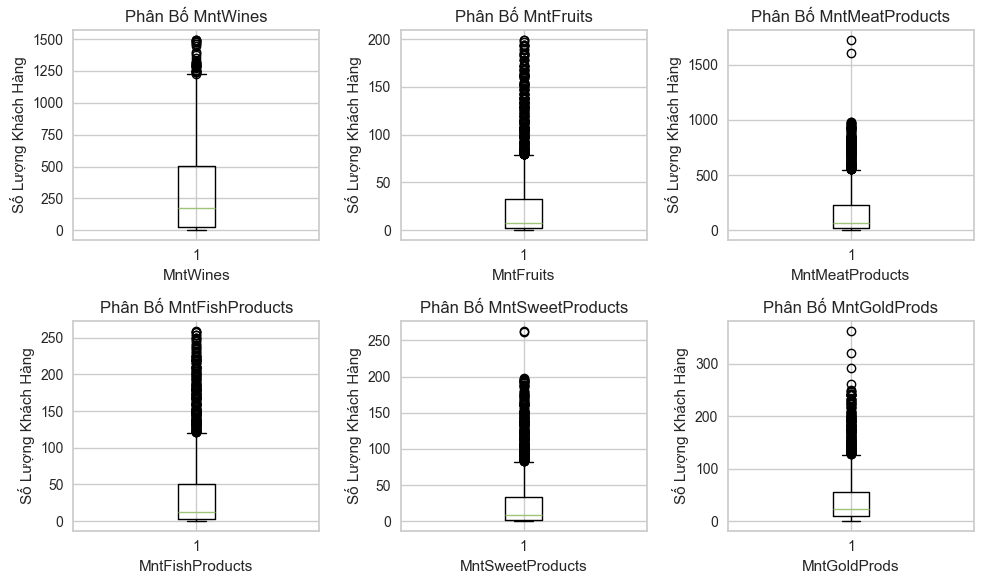

In [32]:
plt.figure(figsize=(10, 6))
for i, col in enumerate(product):
    plt.subplot(2, 3, i+1)
    plt.boxplot(df[col])
    plt.title(f'Phân Bố {col}')
    plt.xlabel(col)
    plt.ylabel('Số Lượng Khách Hàng')
    plt.tight_layout()

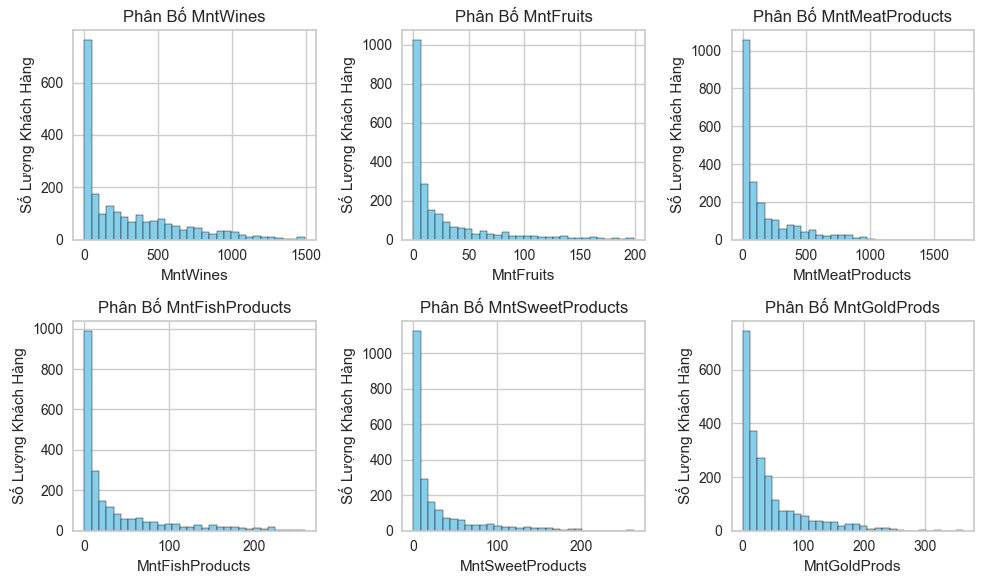

In [33]:
plt.figure(figsize=(10, 6))
for i, col in enumerate(product):
    plt.subplot(2, 3, i+1)
    plt.hist(df[col], bins=30, color='skyblue', edgecolor='black')
    plt.title(f'Phân Bố {col}')
    plt.xlabel(col)
    plt.ylabel('Số Lượng Khách Hàng')
    plt.tight_layout()

In [34]:
#tính skwewness
# Tính độ lệch (skewness) cho các biến product
product_skew = df[product].skew().sort_values(ascending=False)

print("ĐỘ LỆCH (SKEWNESS) CỦA CÁC BIẾN PRODUCT:")
for p, skew_val in product_skew.items():
    print(f"{p:20} : {skew_val:8.2f}")


ĐỘ LỆCH (SKEWNESS) CỦA CÁC BIẾN PRODUCT:
MntSweetProducts     :     2.13
MntFruits            :     2.11
MntFishProducts      :     1.92
MntMeatProducts      :     1.89
MntGoldProds         :     1.88
MntWines             :     1.17


In [35]:
product

['MntWines',
 'MntFruits',
 'MntMeatProducts',
 'MntFishProducts',
 'MntSweetProducts',
 'MntGoldProds']

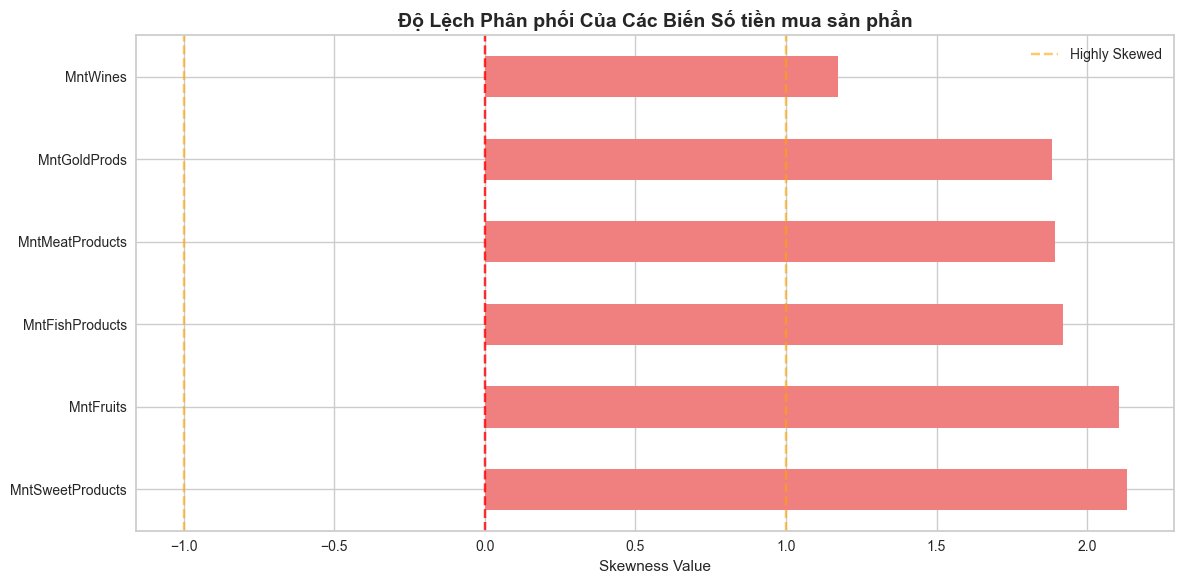

In [36]:
# Visualize nhanh
plt.figure(figsize=(12, 6))
product_skew.plot(kind='barh', color='lightcoral')
plt.title('Độ Lệch Phân phối Của Các Biến Số tiền mua sản phẩn', fontsize=14, fontweight='bold')
plt.xlabel('Skewness Value')
plt.axvline(x=0, color='red', linestyle='--', alpha=0.8)
plt.axvline(x=1, color='orange', linestyle='--', alpha=0.6, label='Highly Skewed')
plt.axvline(x=-1, color='orange', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
#xử lí longtail bằng Yeo-Johnson Transformation

from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method='yeo-johnson')
df[product] = pt.fit_transform(df[product])

print("Đã transform tất cả biến product thành công!")
print(df[product].head())
print("Skewness sau khi transform:")
print(df[product].skew().round(3))

Đã transform tất cả biến product thành công!
   MntWines  MntFruits  MntMeatProducts  MntFishProducts  MntSweetProducts  \
0  1.055941   1.409684         1.428179         1.606007          1.386534   
1 -1.215767  -0.986966        -1.381665        -0.872328         -0.974474   
2  0.742915   1.063343         0.447610         1.330502          0.548499   
3 -1.215767  -0.382531        -0.710223        -0.099999         -0.522834   
4  0.118989   0.985726         0.399590         0.787412          0.695645   

   MntGoldProds  
0      1.091348  
1     -0.944808  
2      0.446520  
3     -1.050052  
4     -0.347264  
Skewness sau khi transform:
MntWines           -0.148
MntFruits           0.018
MntMeatProducts    -0.018
MntFishProducts    -0.012
MntSweetProducts    0.019
MntGoldProds       -0.030
dtype: float64


### Promotion

In [38]:
df.NumDealsPurchases.value_counts()

NumDealsPurchases
1     966
2     497
3     296
4     188
5      94
6      61
0      41
7      40
8      14
9       8
15      5
11      5
10      5
12      4
13      3
Name: count, dtype: int64

Text(0.5, 0, 'Số Lần Mua Hàng Qua Khuyến Mãi')

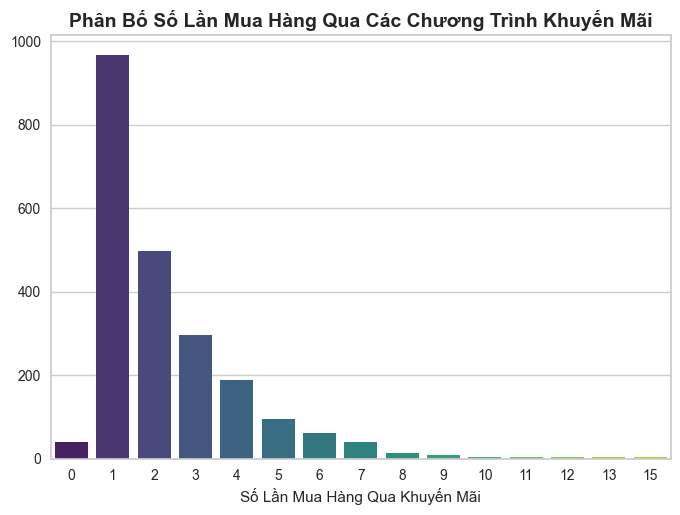

In [39]:
n = df.NumDealsPurchases.value_counts()
sns.barplot(x=n.index, y=n.values, palette='viridis')
plt.title('Phân Bố Số Lần Mua Hàng Qua Các Chương Trình Khuyến Mãi', fontsize=14, fontweight='bold')
plt.xlabel('Số Lần Mua Hàng Qua Khuyến Mãi')

In [40]:
#gom thành 3 nhóm cho hợp lí 1: mua ít, 2: mua vừa, 3: mua nhiều
def categorize_deals_purchases(x):
    if x <= 2:
        return 1          # 0-2 deals (0,1,2)
    elif x <= 5:
        return 2        # 3-5 deals (3,4,5)  
    else:
        return 3       # 6+ deals (6,7,8,9,...)

# Áp dụng categorization
df['NumDealsPurchases'] = df['NumDealsPurchases'].apply(categorize_deals_purchases)


Text(0.5, 0, 'Số Lần Mua Hàng Qua Khuyến Mãi')

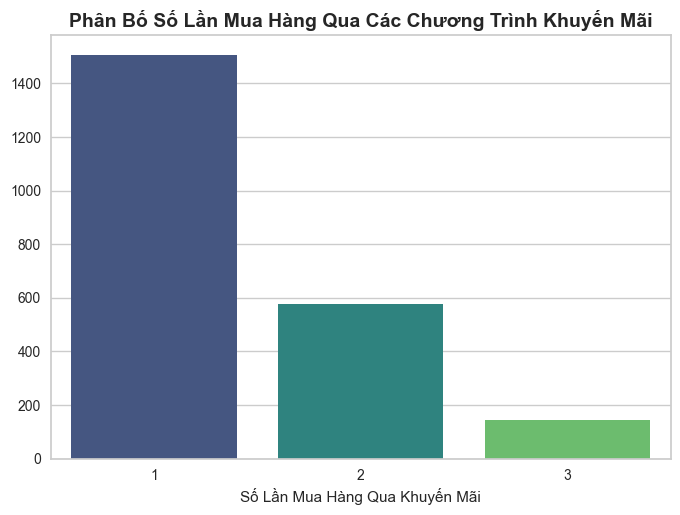

In [41]:
n = df.NumDealsPurchases.value_counts()
sns.barplot(x=n.index, y=n.values, palette='viridis')
plt.title('Phân Bố Số Lần Mua Hàng Qua Các Chương Trình Khuyến Mãi', fontsize=14, fontweight='bold')
plt.xlabel('Số Lần Mua Hàng Qua Khuyến Mãi')
## đã gom nhóm xong khá ổn

In [42]:
promotion

['NumDealsPurchases',
 'AcceptedCmp1',
 'AcceptedCmp2',
 'AcceptedCmp3',
 'AcceptedCmp4',
 'AcceptedCmp5',
 'Response']

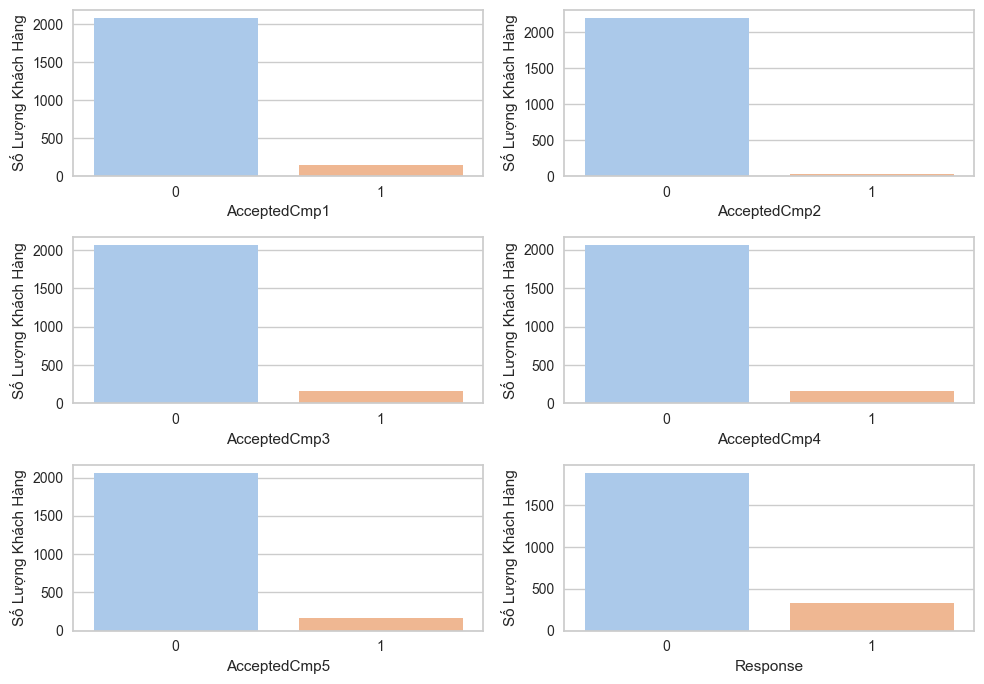

In [43]:
plt.figure(figsize=(10,7))
for i,col in enumerate([
 'AcceptedCmp1',
 'AcceptedCmp2',
 'AcceptedCmp3',
 'AcceptedCmp4',
 'AcceptedCmp5',
 'Response']):
    if col == 'NumDealsPurchases':
        continue
    plt.subplot(3, 2, i+1)
    sns.countplot(x=df[col], palette='pastel')
    plt.xlabel(col)
    plt.ylabel('Số Lượng Khách Hàng')
plt.tight_layout()
plt.show()

In [44]:
#### các giá trị chấp nhận quá bé -> Không có giá trị phân phân cụm bỏ khỏi mô hình clustering
df = df.drop(columns=['AcceptedCmp1','AcceptedCmp2','AcceptedCmp3','AcceptedCmp4','AcceptedCmp5','Response'])

Xử lí Place

In [45]:
df[place].describe()

,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
count,2227.000000,2227.000000,2227.000000,2227.000000
mean,4.100584,2.632241,5.811855,5.337674
std,2.776609,2.792607,3.243500,2.413282
min,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,3.000000,3.000000
50%,4.000000,2.000000,5.000000,6.000000
75%,6.000000,4.000000,8.000000,7.000000
max,27.000000,28.000000,13.000000,20.000000


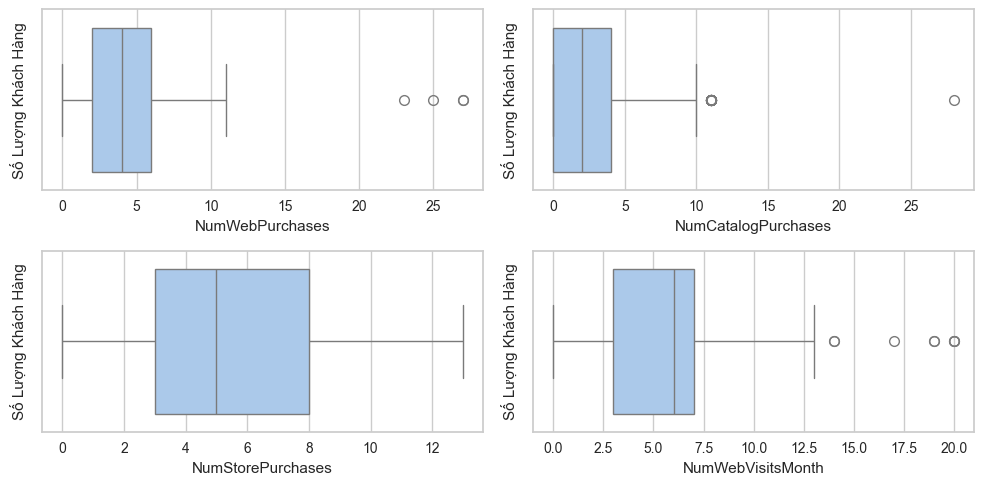

In [46]:
plt.figure(figsize=(10,7))
for i,col in enumerate(place):
    plt.subplot(3, 2, i+1)
    sns.boxplot(x=df[col], palette='pastel')
    plt.xlabel(col)
    plt.ylabel('Số Lượng Khách Hàng')
plt.tight_layout()
plt.show()

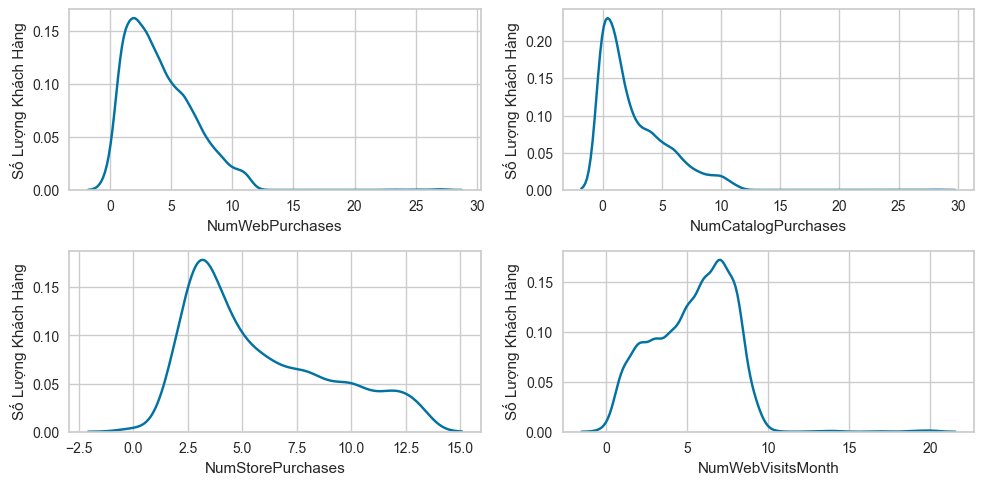

In [47]:
plt.figure(figsize=(10,7))
for i,col in enumerate(place):
    plt.subplot(3, 2, i+1)
    sns.kdeplot(x=df[col], palette='pastel')
    plt.xlabel(col)
    plt.ylabel('Số Lượng Khách Hàng')
plt.tight_layout()
plt.show()

In [48]:
#đếm số lượng outliers
# Hàm detect outliers bằng IQR method
def count_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    return len(outliers)


outliers_summary = {}
for col in place:
    outlier_count = count_outliers_iqr(df[col])
    outliers_summary[col] = outlier_count
    print(f"{col:25} : {outlier_count:3d} outliers")



NumWebPurchases           :   4 outliers
NumCatalogPurchases       :  20 outliers
NumStorePurchases         :   0 outliers
NumWebVisitsMonth         :   8 outliers


In [49]:
#số lượng outliers không nhiều nên bỏ đi không ảnh hưởng
for col in place:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

### Chuẩn hóa và PCA

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2194 entries, 0 to 2239
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year_Birth           2194 non-null   int64  
 1   Education            2194 non-null   object 
 2   Marital_Status       2194 non-null   object 
 3   Income               2194 non-null   float64
 4   Recency              2194 non-null   int64  
 5   MntWines             2194 non-null   float64
 6   MntFruits            2194 non-null   float64
 7   MntMeatProducts      2194 non-null   float64
 8   MntFishProducts      2194 non-null   float64
 9   MntSweetProducts     2194 non-null   float64
 10  MntGoldProds         2194 non-null   float64
 11  NumDealsPurchases    2194 non-null   int64  
 12  NumWebPurchases      2194 non-null   int64  
 13  NumCatalogPurchases  2194 non-null   int64  
 14  NumStorePurchases    2194 non-null   int64  
 15  NumWebVisitsMonth    2194 non-null   int64 

In [51]:
# chia thành cate và num
num = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cate = df.select_dtypes(include=['object']).columns.tolist()

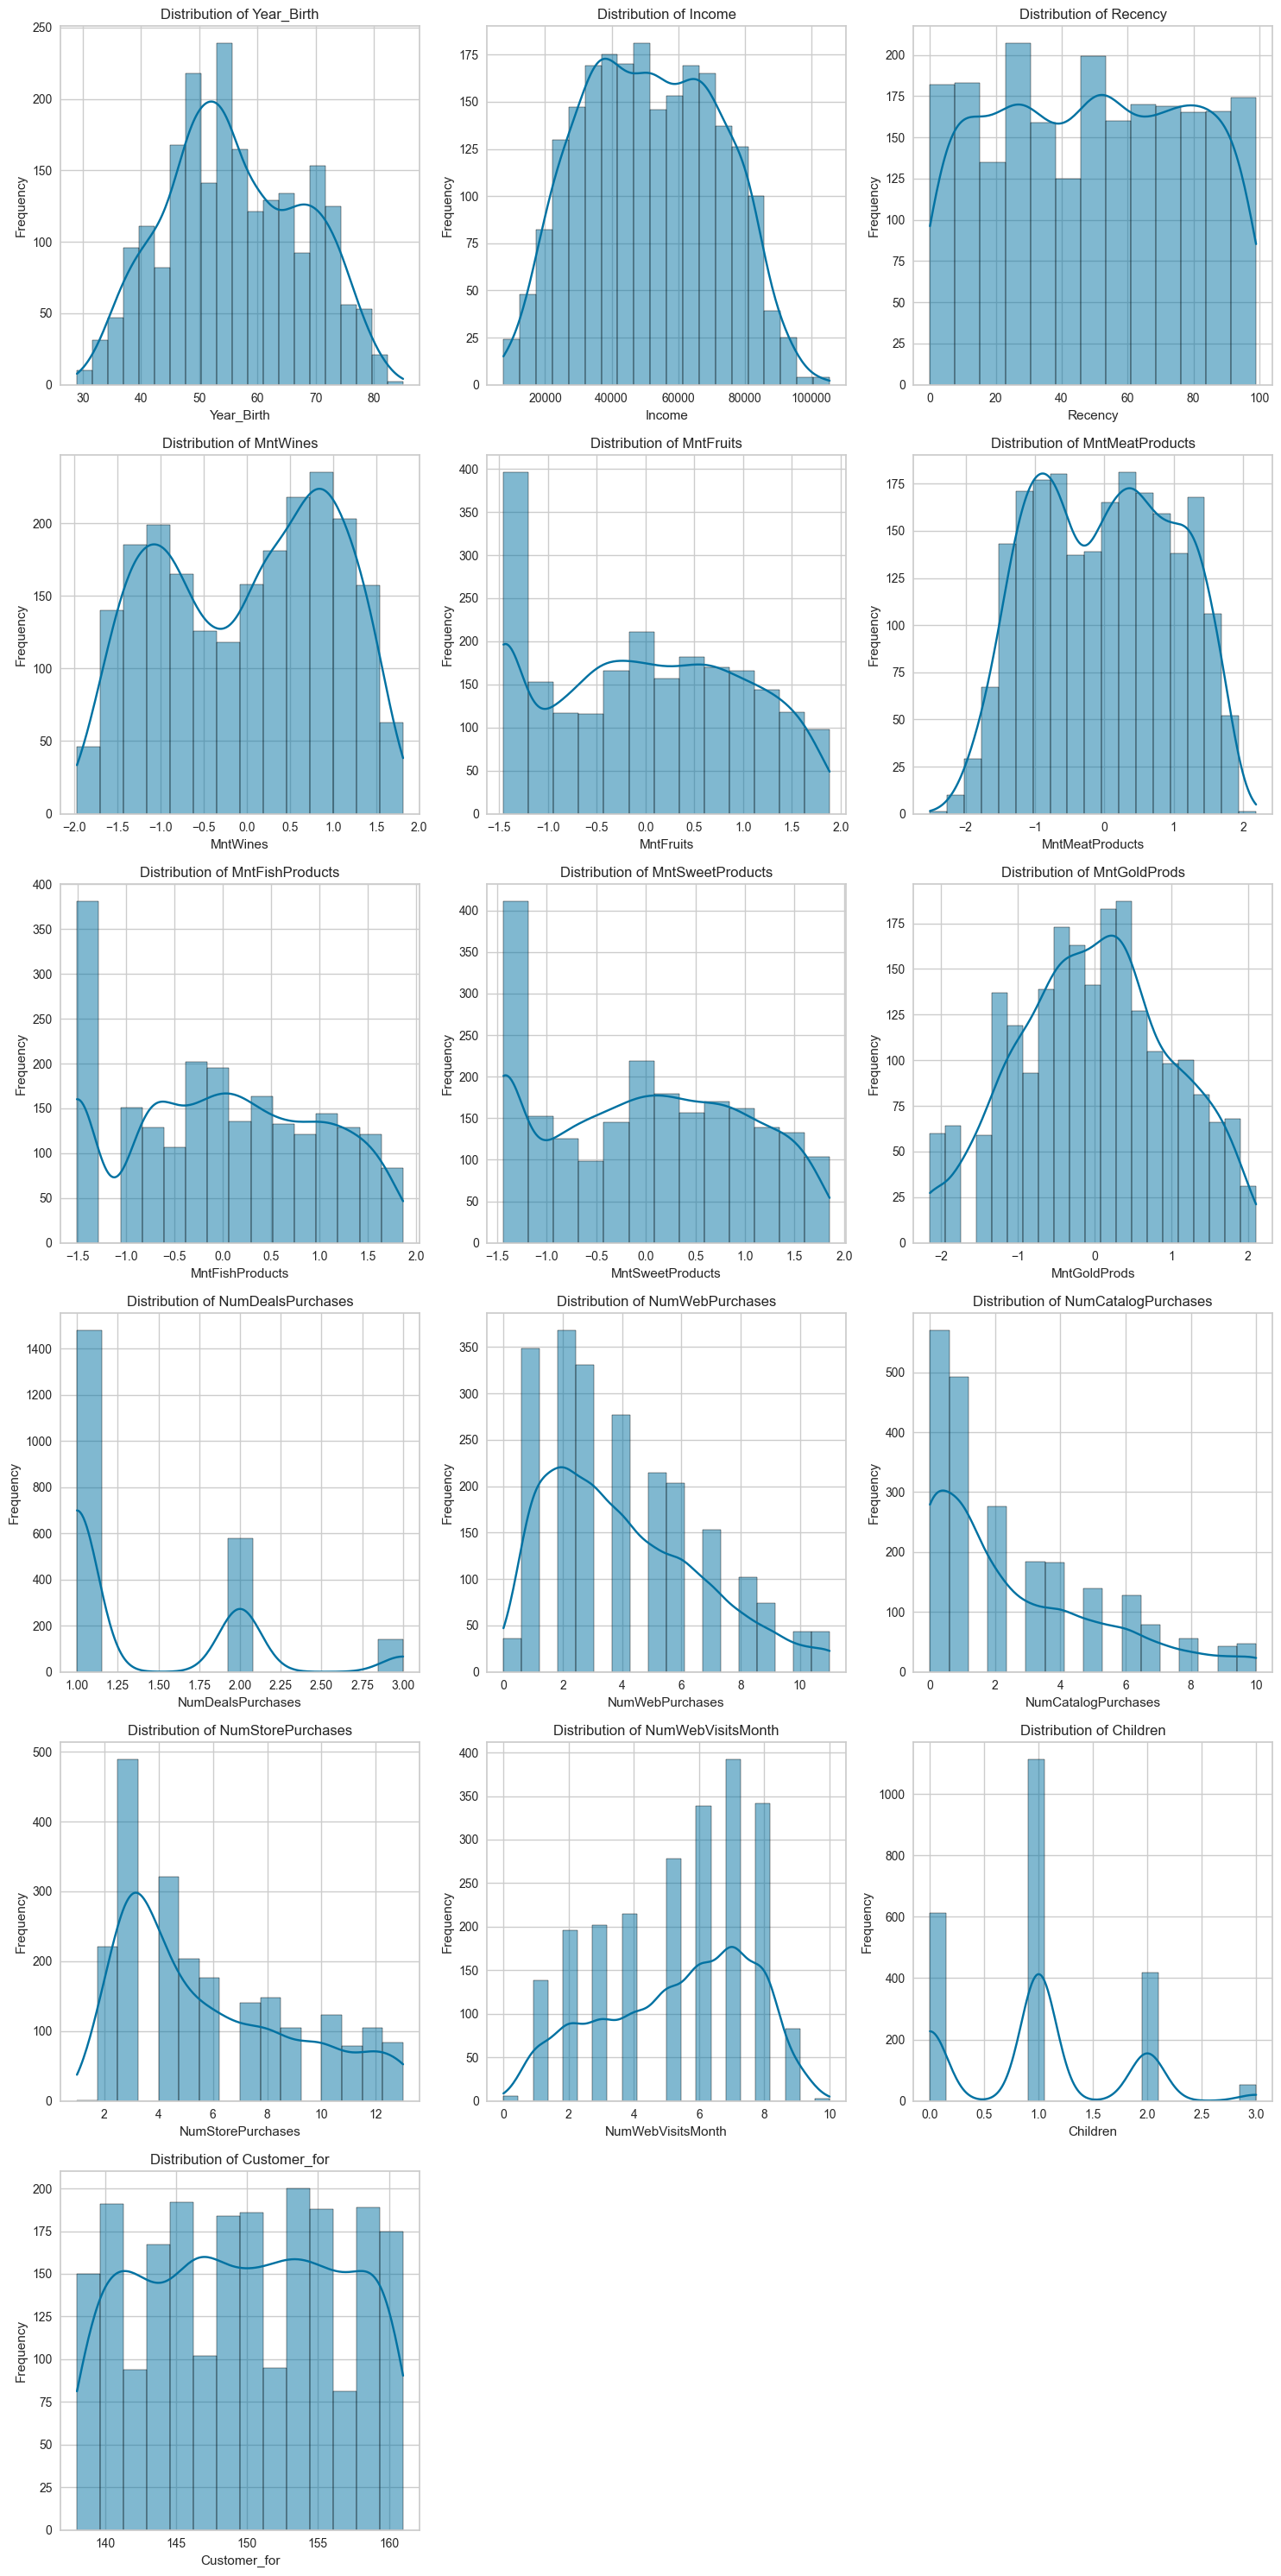

In [52]:

# Dynamic grid based on number of numeric columns to avoid subplot index errors
ncols = 3
nrows = int(np.ceil(len(num) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 5 * nrows))
axes = np.array(axes).reshape(-1)

for i, column in enumerate(num):
    ax = axes[i]
    # use histplot (distplot is deprecated) with KDE
    sns.histplot(df[column], kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel('Frequency')

# Remove any unused subplots
for j in range(len(num), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [53]:
# Xử lý Ordinal Encoding cho Education
education_order = ['Basic', '2n Cycle', 'Graduation', 'Master', 'PhD']

# Tạo mapping dictionary
education_mapping = {level: idx for idx, level in enumerate(education_order)}

# Áp dụng ordinal encoding
df['Education'] = df['Education'].map(education_mapping)

In [54]:
df = pd.get_dummies(df, columns=['Marital_Status'])

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2194 entries, 0 to 2239
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Year_Birth               2194 non-null   int64  
 1   Education                2194 non-null   int64  
 2   Income                   2194 non-null   float64
 3   Recency                  2194 non-null   int64  
 4   MntWines                 2194 non-null   float64
 5   MntFruits                2194 non-null   float64
 6   MntMeatProducts          2194 non-null   float64
 7   MntFishProducts          2194 non-null   float64
 8   MntSweetProducts         2194 non-null   float64
 9   MntGoldProds             2194 non-null   float64
 10  NumDealsPurchases        2194 non-null   int64  
 11  NumWebPurchases          2194 non-null   int64  
 12  NumCatalogPurchases      2194 non-null   int64  
 13  NumStorePurchases        2194 non-null   int64  
 14  NumWebVisitsMonth        2194

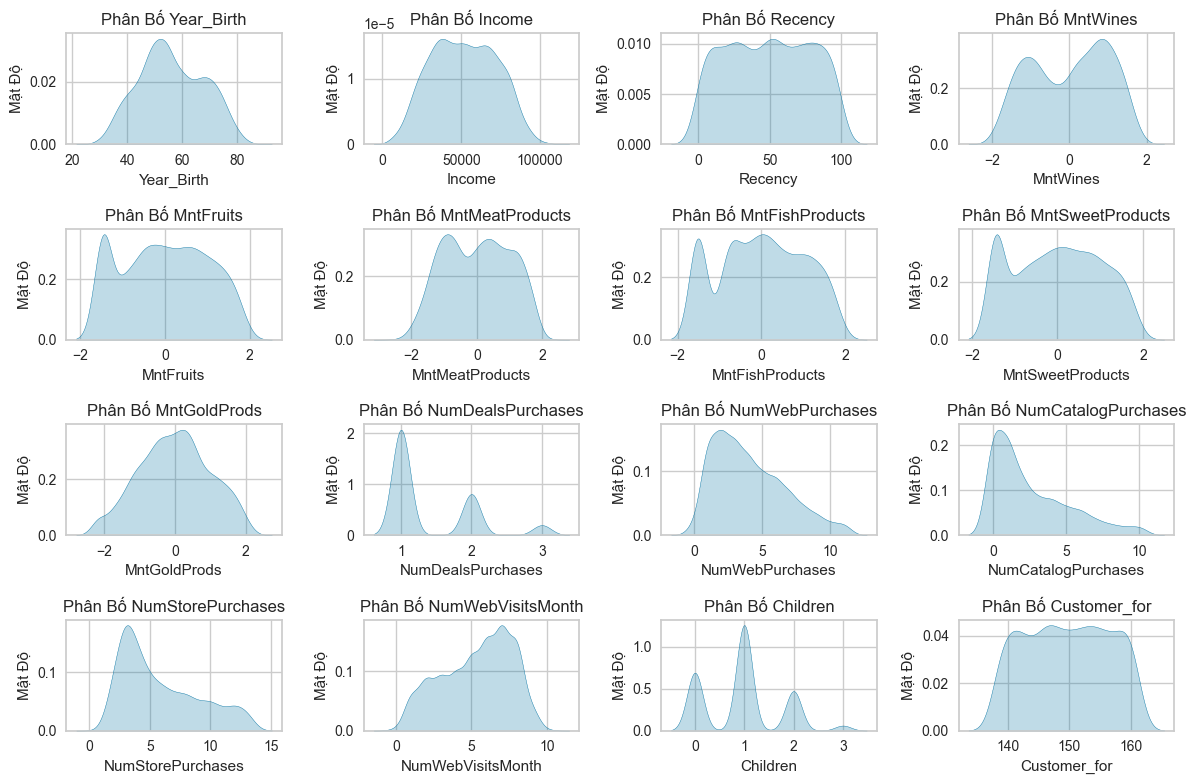

In [56]:
#vẽ phân phối các biến số
plt.figure(figsize=(12, 8))
for i, col in enumerate(num):
    plt.subplot(4, 4, i+1)
    sns.kdeplot(df[col], fill=True)
    plt.title(f'Phân Bố {col}')
    plt.xlabel(col)
    plt.ylabel('Mật Độ')
    plt.tight_layout()

In [57]:
# chuẩn hóa 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

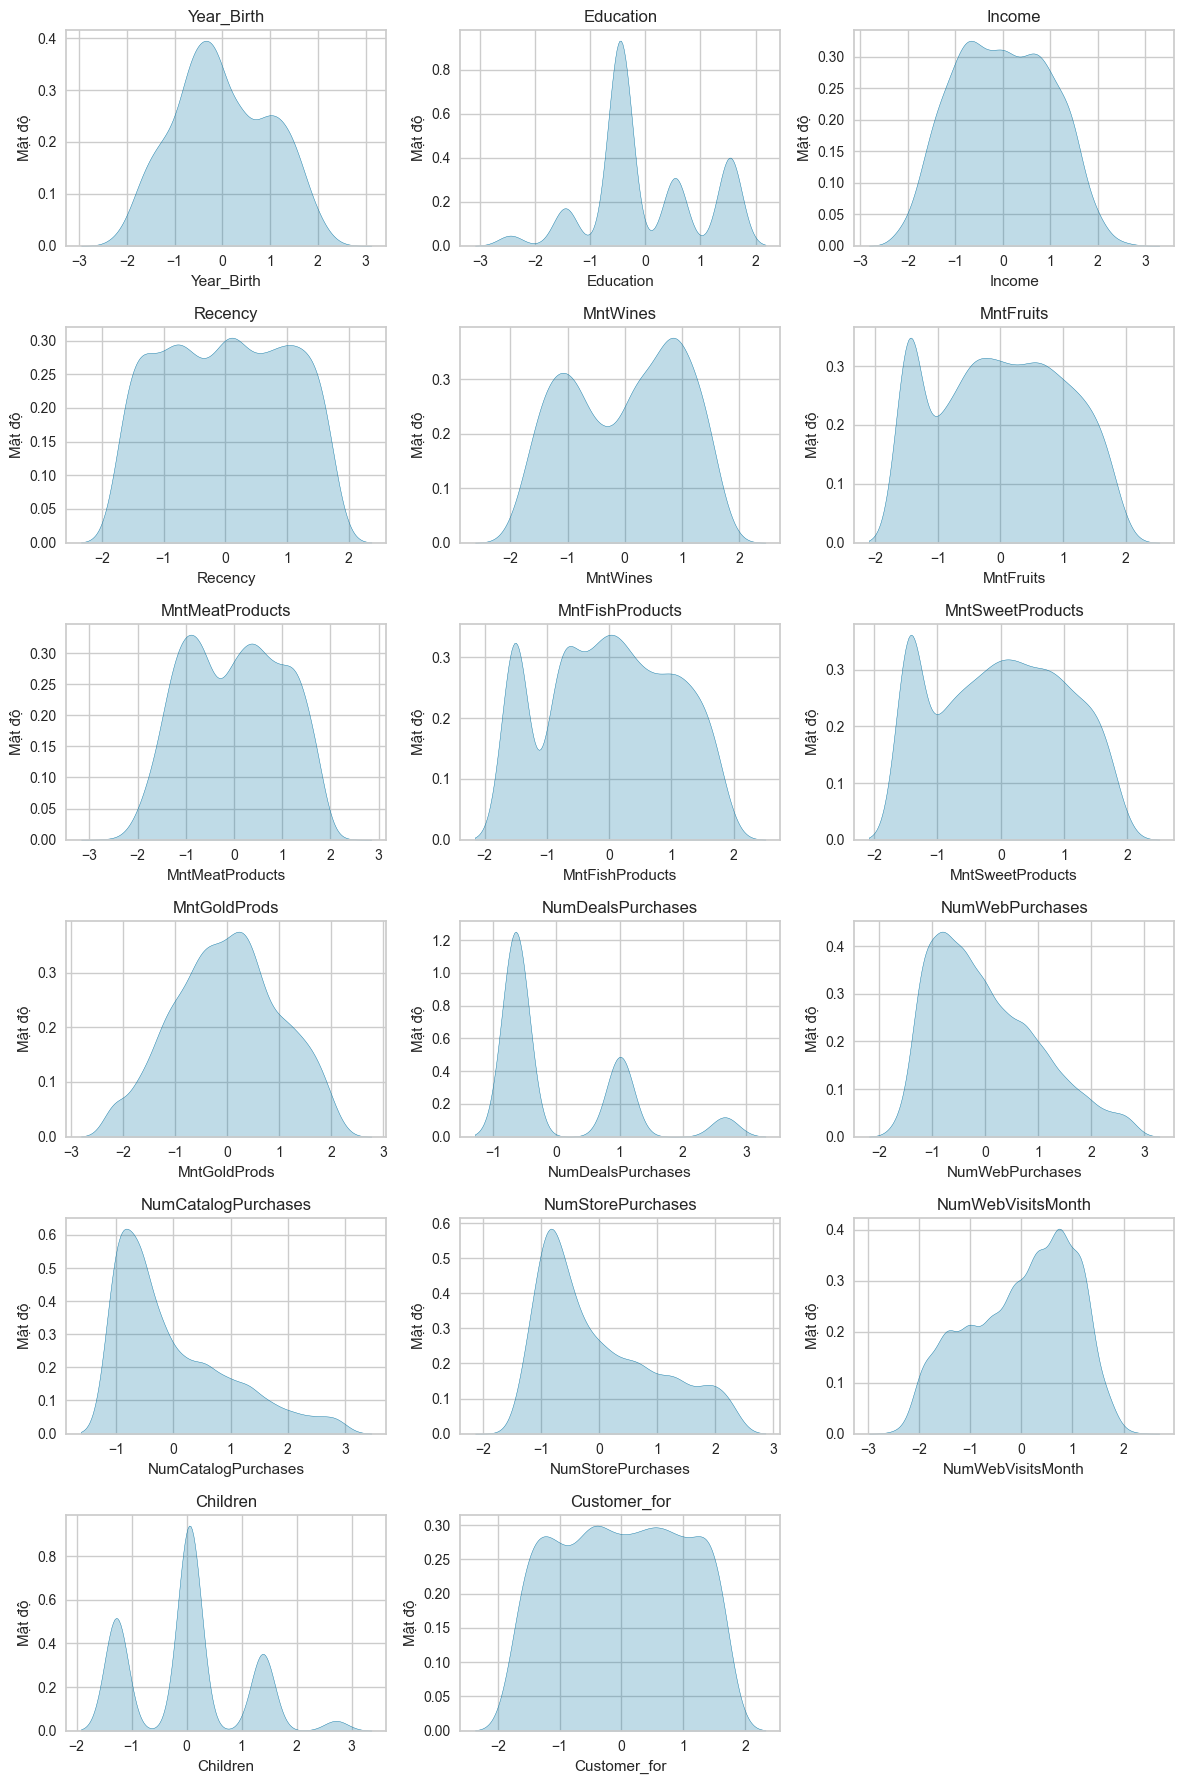

In [61]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[num])
df_scaled = pd.DataFrame(X_scaled, columns=num)

# Tính số hàng cần thiết (mỗi hàng 4 biểu đồ)
rows = math.ceil(len(num) / 3)

# Vẽ phân phối sau khi chuẩn hóa
plt.figure(figsize=(12, 3 * rows))
plot_idx = 1
for col in num:
    if df_scaled[col].nunique() > 1 and not df_scaled[col].isnull().all():
        plt.subplot(rows, 3, plot_idx)
        sns.kdeplot(df_scaled[col], fill=True)
        plt.title(f'{col}')
        plt.xlabel(col)
        plt.ylabel('Mật độ')
        plot_idx += 1

plt.tight_layout()
plt.show()

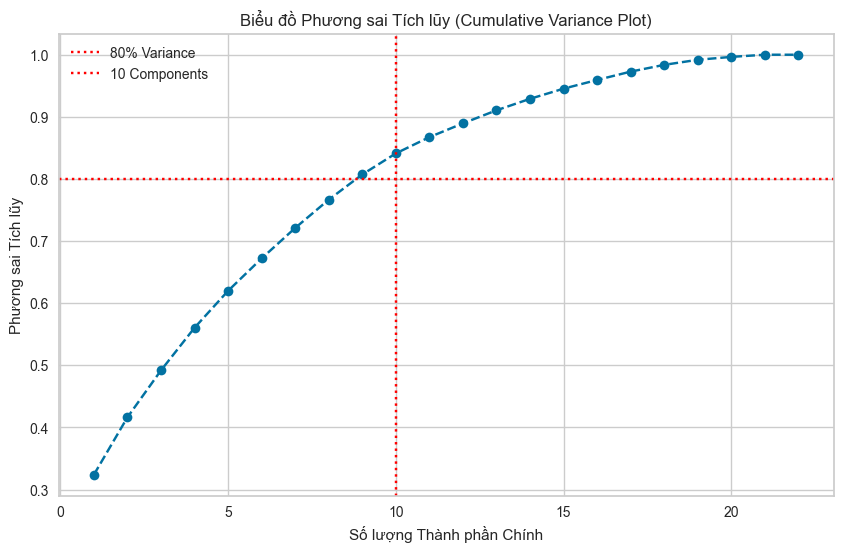

Số thành phần cần thiết để giữ 80% phương sai: 10


In [59]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Chạy PCA với tất cả các thành phần để kiểm tra
pca_full = PCA(n_components=None)
pca_full.fit(X_scaled)

# Tính phương sai tích lũy
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Tìm số thành phần để đạt 80%
k = np.argmax(cumulative_variance > 0.81) + 1

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.title('Biểu đồ Phương sai Tích lũy (Cumulative Variance Plot)')
plt.xlabel('Số lượng Thành phần Chính')
plt.ylabel('Phương sai Tích lũy')
plt.grid(True)

# Đánh dấu mốc 80%
plt.axhline(y=0.80, color='red', linestyle=':', label='80% Variance')
plt.axvline(x=k, color='red', linestyle=':', label=f'{k} Components')
plt.legend(loc='best')
plt.show()

print(f"Số thành phần cần thiết để giữ 80% phương sai: {k}")

In [60]:
# Sử dụng số thành phần k_80 đã tìm thấy
k_components = 10

pca_final = PCA(n_components=k_components)
X_pca = pca_final.fit_transform(X_scaled)

print(f"Đã giảm chiều dữ liệu từ {X_scaled.shape[1]} xuống {X_pca.shape[1]} thành phần.")

Đã giảm chiều dữ liệu từ 22 xuống 10 thành phần.


In [61]:
from sklearn.cluster import AffinityPropagation
from sklearn.metrics import silhouette_score
import time

print("Đang chạy Affinity Propagation (AP) trên dữ liệu PCA...")
print("Việc này có thể mất vài phút...")

start_time = time.time()

# Khởi tạo AP
ap = AffinityPropagation(damping=0.9, random_state=42,preference=-5000)

# Fit mô hình
ap.fit(X_pca)

end_time = time.time()

# Lấy kết quả
ap_labels = ap.labels_
ap_centers_indices = ap.cluster_centers_indices_
ap_n_clusters = len(ap_centers_indices)

print(f"\nAP hoàn tất sau {end_time - start_time:.2f} giây.")
print(f"Số cụm (exemplars) tìm thấy: {ap_n_clusters}")

# Đánh giá
if ap_n_clusters > 1:
    score = silhouette_score(X_pca, ap_labels)
    print(f"Silhouette Score: {score:.4f}")
else:
    print("AP chỉ tìm thấy 1 cụm, không thể tính Silhouette Score.")

Đang chạy Affinity Propagation (AP) trên dữ liệu PCA...
Việc này có thể mất vài phút...

AP hoàn tất sau 4.79 giây.
Số cụm (exemplars) tìm thấy: 5
Silhouette Score: 0.1356


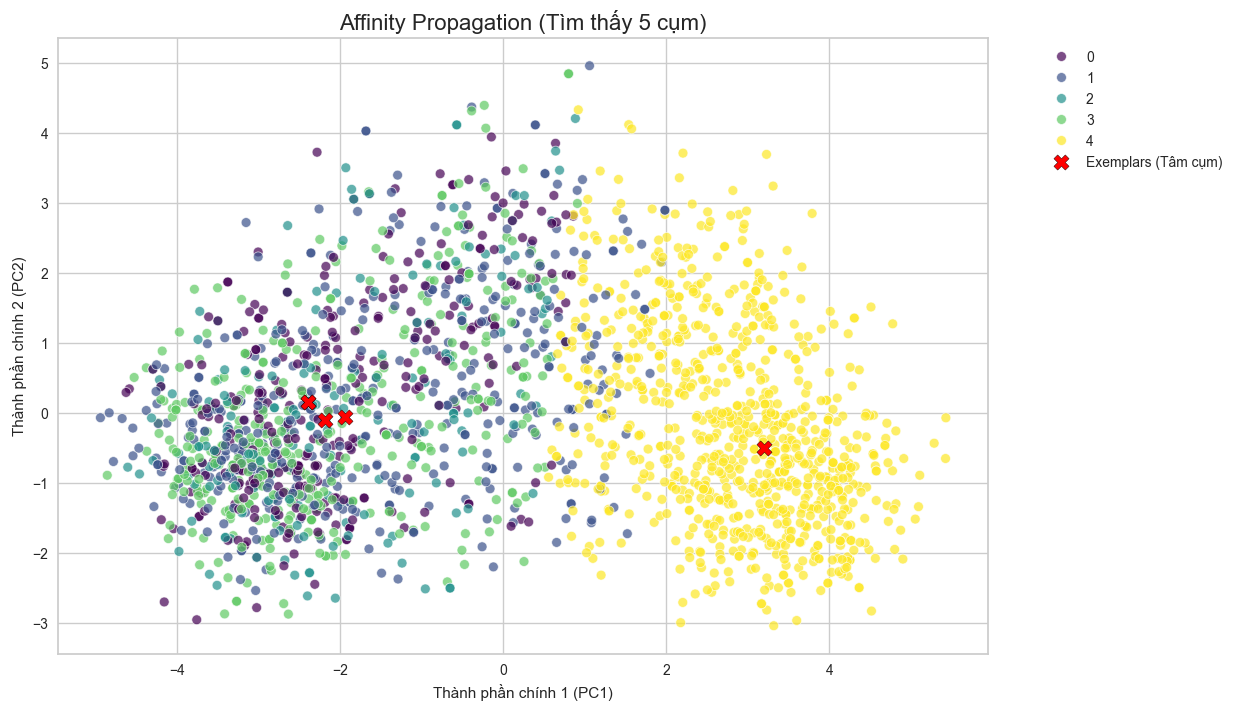

In [62]:
import seaborn as sns

# Lấy tọa độ tâm cụm (exemplars)
ap_centers_pca = ap.cluster_centers_

# Tạo DataFrame để vẽ
df_pca_results = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(k_components)])
df_pca_results['AP_Cluster'] = ap_labels

# Vẽ
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_pca_results, x='PC1', y='PC2', hue='AP_Cluster', 
                palette='viridis', legend='full', s=50, alpha=0.7)

# Vẽ các tâm cụm (Exemplars)
plt.scatter(ap_centers_pca[:, 0], ap_centers_pca[:, 1], s=120, c='red', 
            marker='X', label='Exemplars (Tâm cụm)', edgecolors='black')

plt.title(f'Affinity Propagation (Tìm thấy {ap_n_clusters} cụm)', fontsize=16)
plt.xlabel('Thành phần chính 1 (PC1)')
plt.ylabel('Thành phần chính 2 (PC2)')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2)
plt.grid(True)
plt.show()